# EM algorithm for unsupervised and semi-supervised learning

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import multivariate_normal
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans


# 1. EM algorithm for Gaussian mixtures

We have worked out the calculations for a Gaussian mixture with $d = 1$. Let’s now do for $d = 2$.

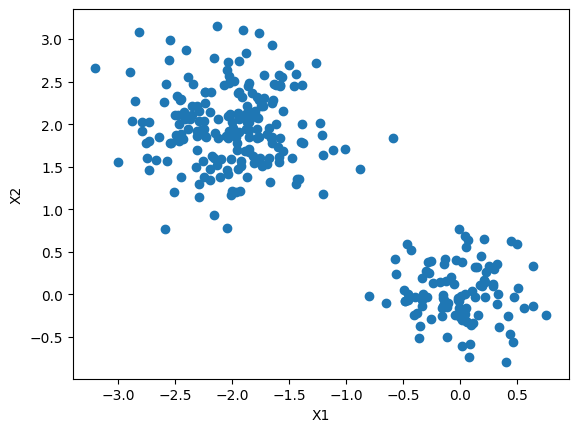

In [ ]:
X1 = np.random.multivariate_normal(
    mean=[0, 0],
    cov=0.1 * np.eye(2),
    size=100
)

X2 = np.random.multivariate_normal(
    mean=[-2, 2],
    cov=0.2 * np.eye(2),
    size=200
)

X = np.vstack((X1, X2))

plt.scatter(X[:, 0], X[:, 1])
plt.xlabel("X1")
plt.ylabel("X2")
plt.show()

## Question 1.1.

Which is the model? Which are the parameters of the EM algorithm (dimensions, constraints)?

## Correction de 1.1.

For each observation $X_i\in \mathbb{R}^2$, the model is
$$p(X_i|\Theta)=\sum_{k=1}^K \pi_k p_k(X|\mu_k,\Sigma_k),$$
with
* $K=2$ (there is two groups),
* $(\pi_k)_{k=1,2}$ the proportions of the group, with $\pi_k>0$ and $\sum_k \pi_k=1$,
* $\mu_k\in \mathbb{R}^2$ the means in each group,
* $\Sigma_k \in \mathbb{R}^{2\times2}$ the covariance matrices in each group, each covariance matrix must be symmetric positive definite.

The parameter is $\Theta=(\pi_k,\mu_k,\Sigma_k)_{k=1,2}$.



## Question 1.2.

How to initialize the algorithm? Create a function for the initialization.

*Tip: You will need the posterior probabilities in the following steps. You can create an object here to store them.*

## Correction de 1.2.

We need to initialize the parameters of the Gaussian mixture model: the mixing proportions ($\pi_k$), the means ($\mu_k$) and the covariance matrices ($\Sigma_k$).
Here is the initialization.

In [ ]:
def initialization_EM(X, K=2):
    """
    Initialize the parameters of a Gaussian mixture model
    for the EM algorithm.
    """

    n = X.shape[0]
    d = X.shape[1]

    # Posterior probabilities
    P = np.full((n, K), np.nan)

    # Initial class membership (pi)
    prop = np.full(K, 1 / K)

    # Initial means
    mu = np.random.multivariate_normal(
        mean=np.mean(X, axis=0),
        cov=np.eye(d),
        size=K
    )

    # Initial covariance matrices
    Sigma = np.zeros((K, d, d))

    for k in range(K):
        Sigma[k, :, :] = np.eye(d)

    return P, prop, mu, Sigma

Here:

* `P` will contain the posterior probabilities (or responsibilities) computed during the E-step. It does not need to be initialized with meaningful values;

* `prop` initializes all mixture proportions equally:
$\pi_k^{(0)}=\frac{1}{K}$

* `mu` initializes the $K$ means randomly around the empirical mean of the data:

* `Sigma` initializes all covariance matrices to the identity matrix:
$\Sigma_k^{(0)}=I_p$.


## Question 1.3.

What are the steps of the EM algorithm? Implement the algorithm.

* At each iteration, create an option in your function in order to plot the data using a different color for each group, based on the estimated posterior probabilities.
* Compute the log-likelihood at each iteration and store it.

You can take this structure for the code.

In [ ]:
def EMalgo(X, K=2, n_iter=50, plot=False):

    n = X.shape[0]
    d = X.shape[1]

    # Initialization
    P, prop, mu, Sigma = initialization_EM(X, K=K)

    loglik = []

    for it in range(n_iter):

        # E-step
        ...

        if plot:
            ...

        # M-step
        ...

        # Log-likelihood
        ...
        loglik_it = ...
        loglik.append(loglik_it)


    return {
        "P": P,
        "prop": prop,
        "mu": mu,
        "Sigma": Sigma,
        "loglik": loglik
    }

## Correction de 1.3.

In [ ]:
def EMalgo(X, K=2, n_iter=50, plot=False):

    n = X.shape[0]
    d = X.shape[1]

    # Initialization
    P, prop, mu, Sigma = initialization_EM(X, K=K)

    loglik = []

    for it in range(n_iter):

        # E-step
        for k in range(K):
            P[:, k] = (
                prop[k]
                * multivariate_normal.pdf(
                    X,
                    mean=mu[k],
                    cov=Sigma[k]
                )
            )

        # Normalize the posterior probabilities
        P = P / np.sum(P, axis=1, keepdims=True)

        if plot:
            labels = np.argmax(P, axis=1)

            plt.scatter(X[:, 0], X[:, 1], c=labels)
            plt.scatter(
                mu[:, 0],
                mu[:, 1],
                marker="*",
                s=300
            )

            plt.xlabel("X1")
            plt.ylabel("X2")
            plt.title(f"Iteration {it + 1}")
            plt.pause(0.1)
            plt.clf()

        # M-step
        for k in range(K):

            # Effective number of observations
            Nk = np.sum(P[:, k])

            # Initial class membership (pi)
            prop[k] = Nk / n

            # Mean
            mu[k] = np.sum(
                P[:, k, np.newaxis] * X,
                axis=0
            ) / Nk

            # Centered observations
            Bk = X - mu[k]

            # Covariance matrix
            Sigma[k] = (
                (P[:, k, np.newaxis] * Bk).T @ Bk
            ) / Nk

        # Log-likelihood
        density = np.zeros((n, K))

        for k in range(K):
            density[:, k] = (
                prop[k]
                * multivariate_normal.pdf(
                    X,
                    mean=mu[k],
                    cov=Sigma[k]
                )
            )

        loglik_it = np.sum(
            np.log(np.sum(density, axis=1))
        )

        loglik.append(loglik_it)


    return {
        "P": P,
        "prop": prop,
        "mu": mu,
        "Sigma": Sigma,
        "loglik": loglik
    }

## Question 1.4.

Apply the EM algorithm.
* Plot the data at each iteration.
* Verify that the log-likelihood increases until convergence.

## Correction de 1.4.

We can represent the two groups obtained, with the posterior probabilities.


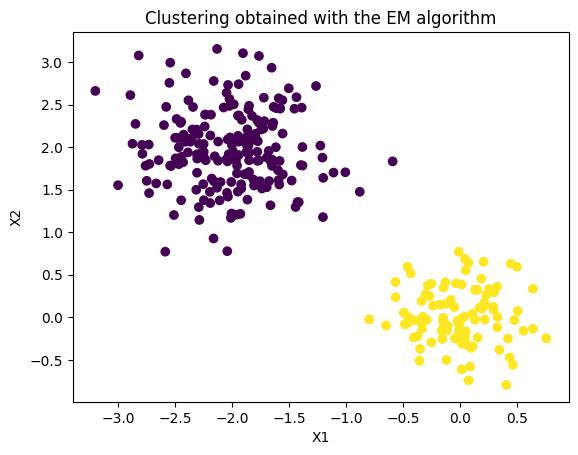

In [ ]:
res_EM = EMalgo(X, K=2, n_iter=50)

groups = np.argmax(res_EM['P'], axis=1)

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=groups
)

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Clustering obtained with the EM algorithm")
plt.show()

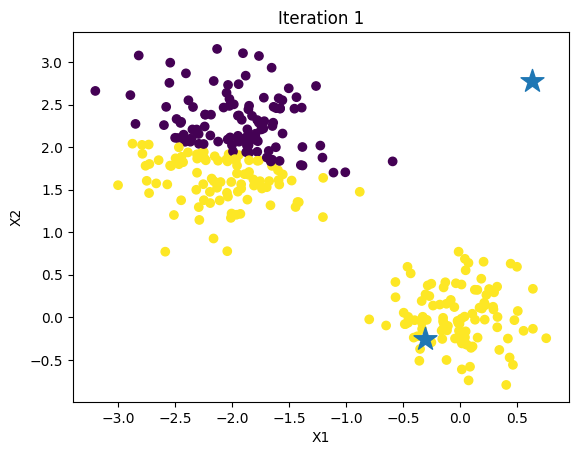

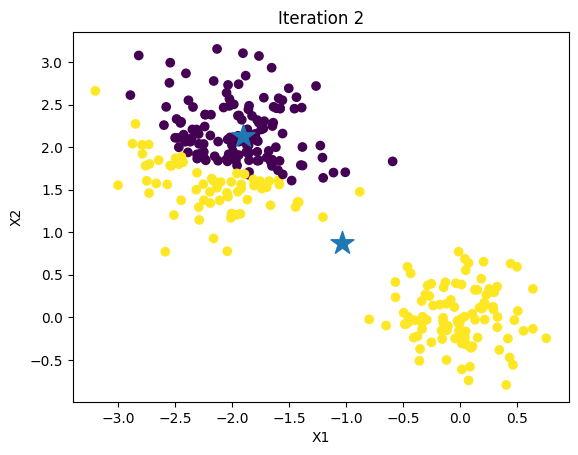

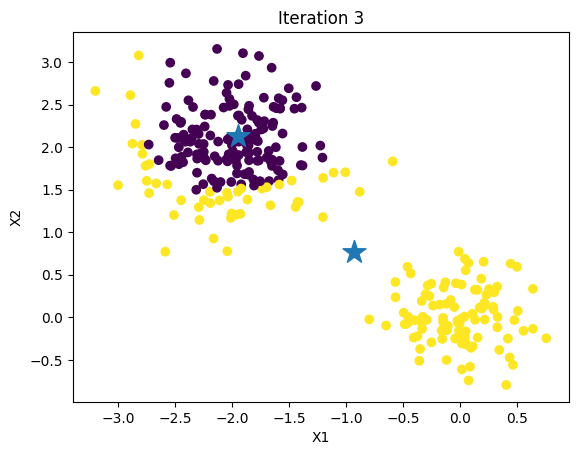

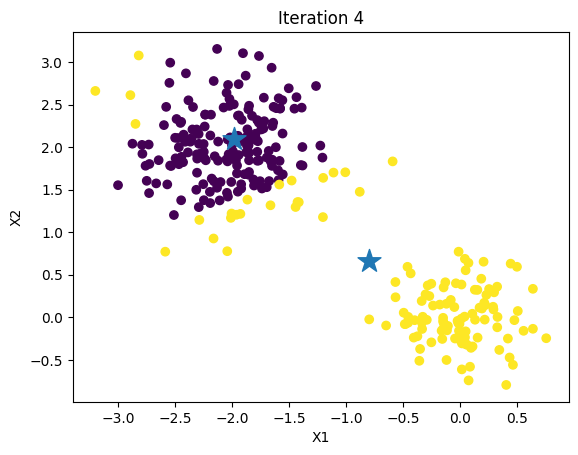

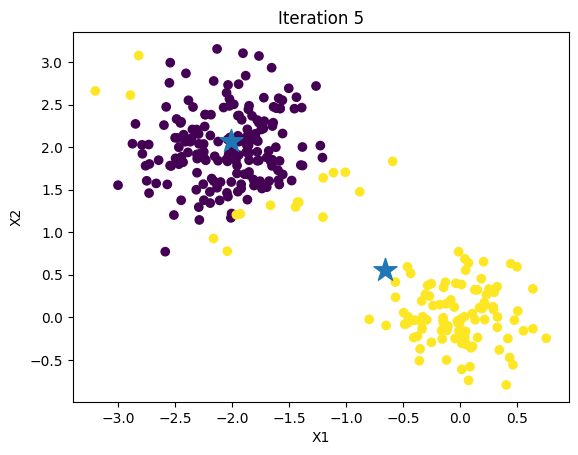

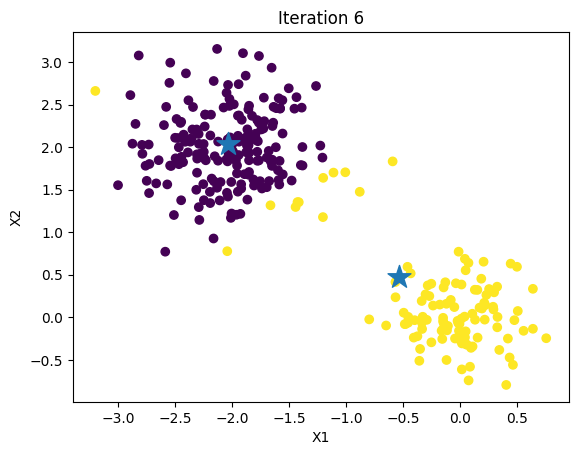

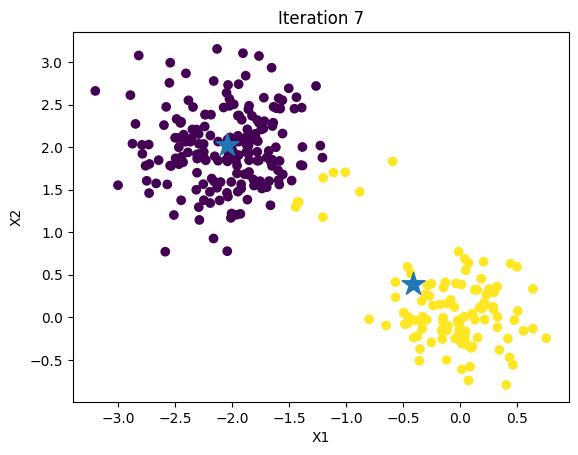

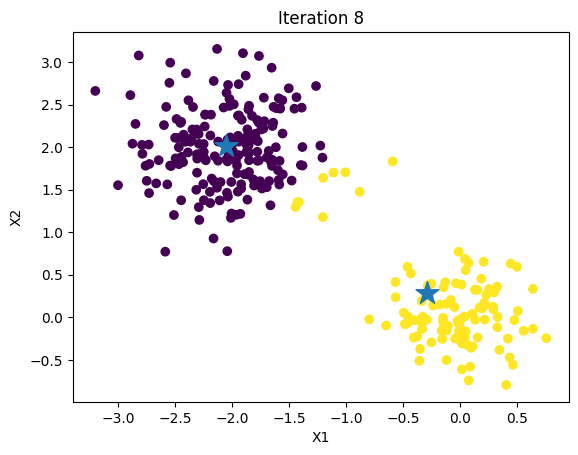

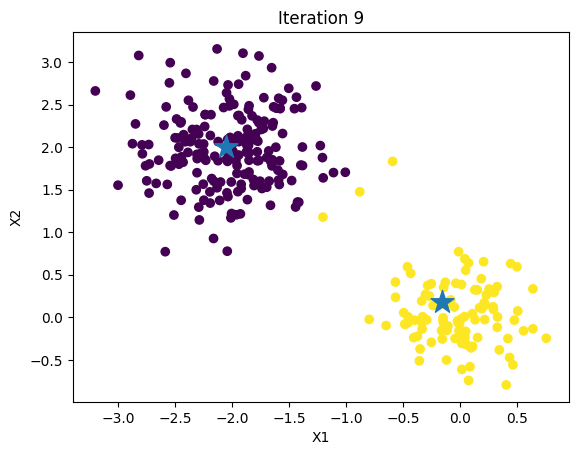

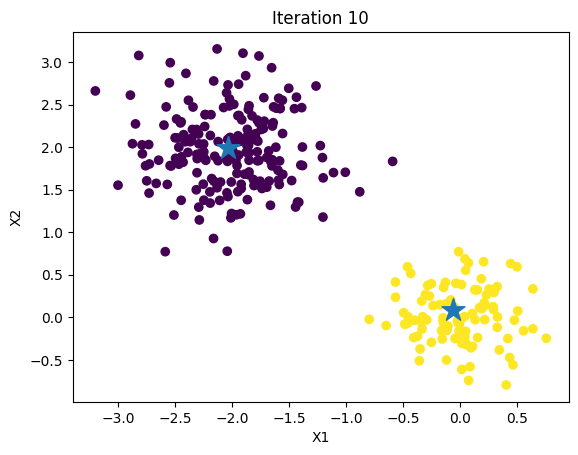

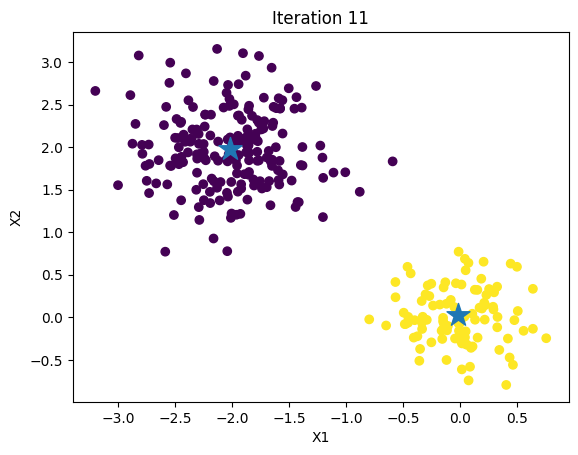

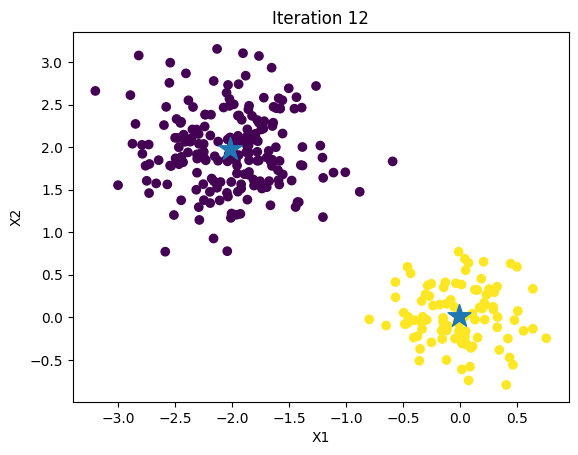

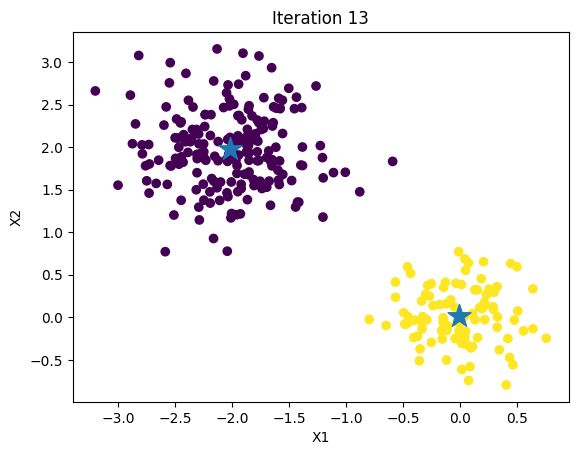

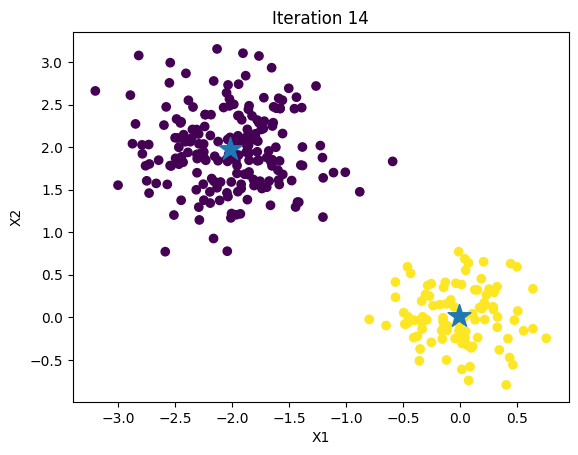

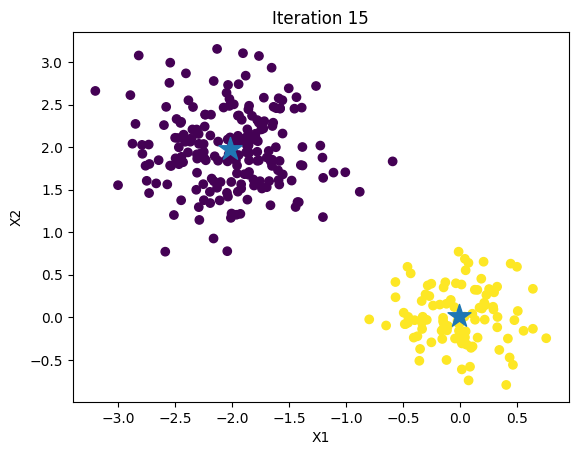

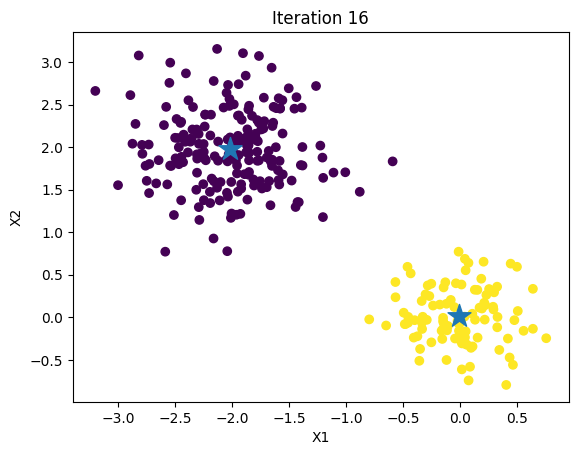

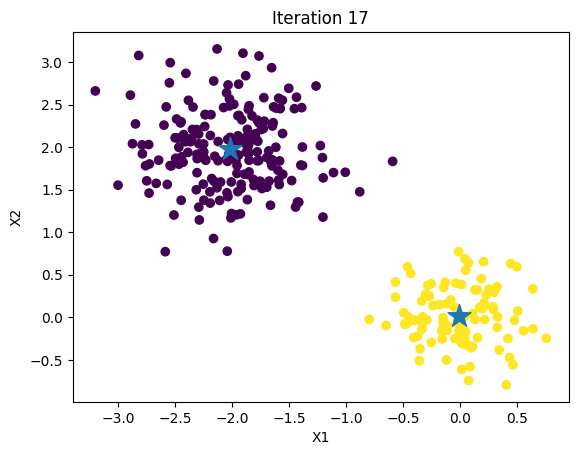

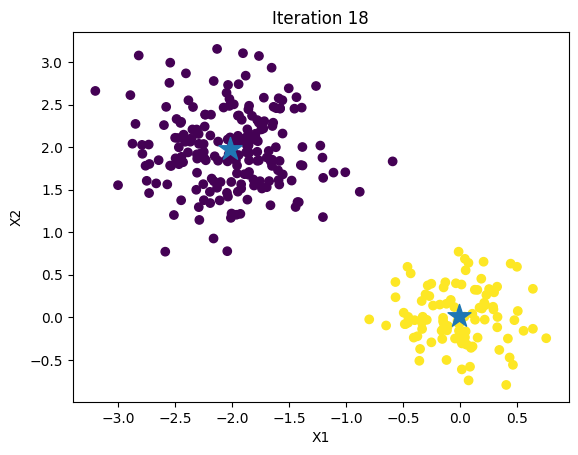

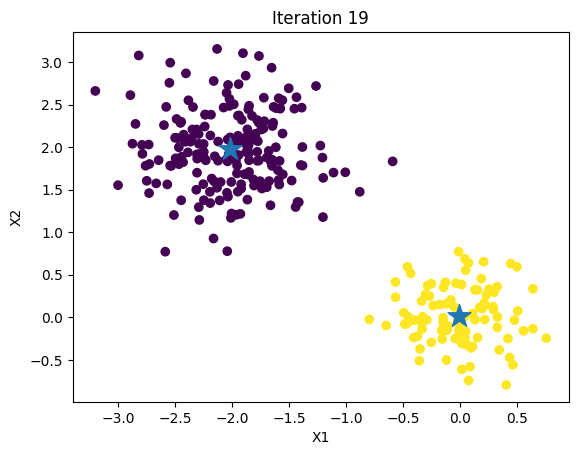

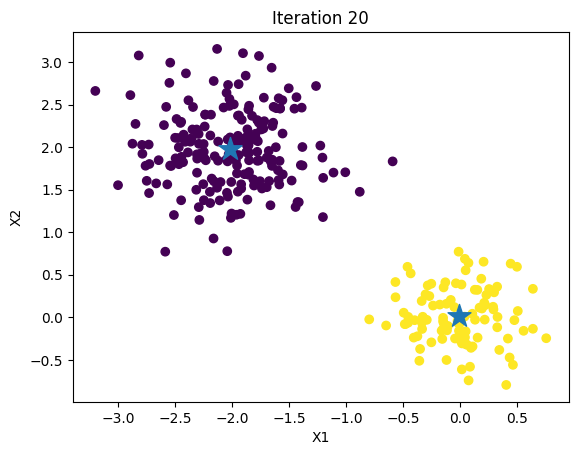

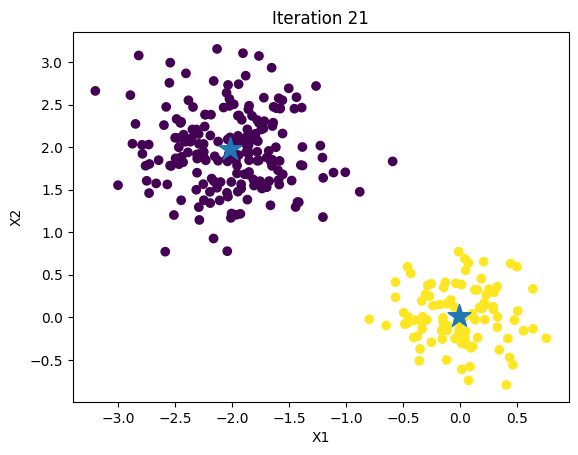

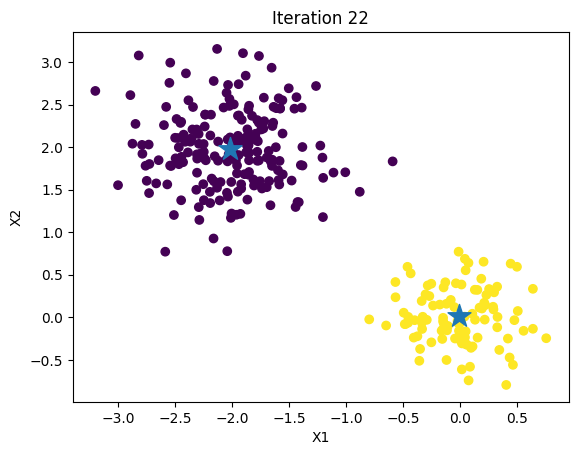

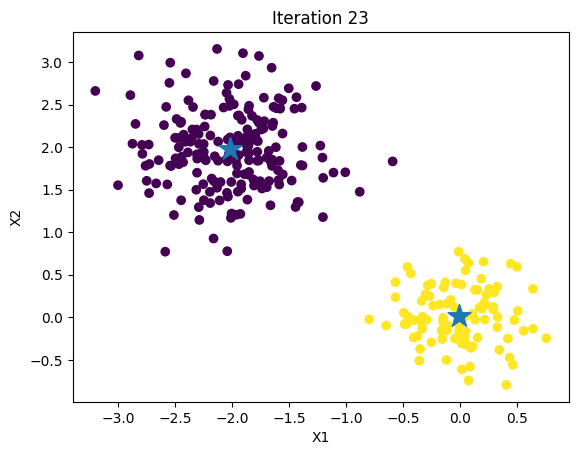

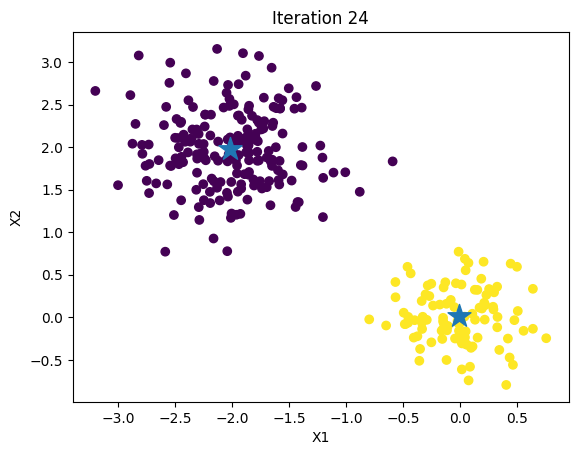

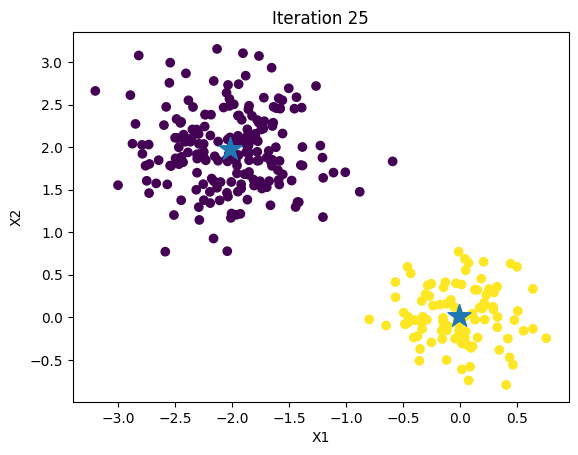

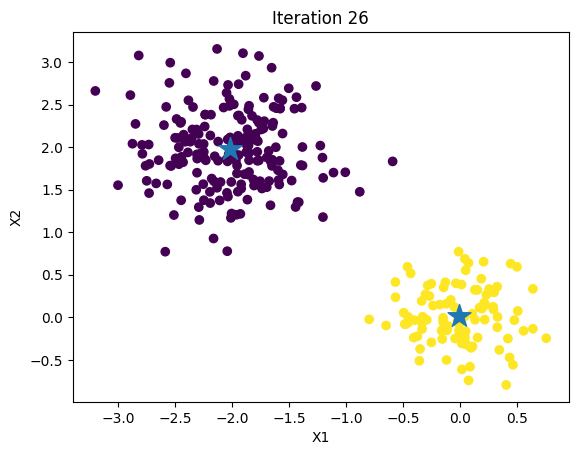

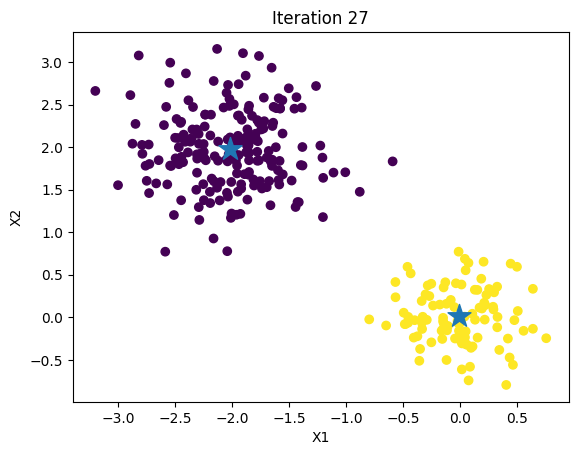

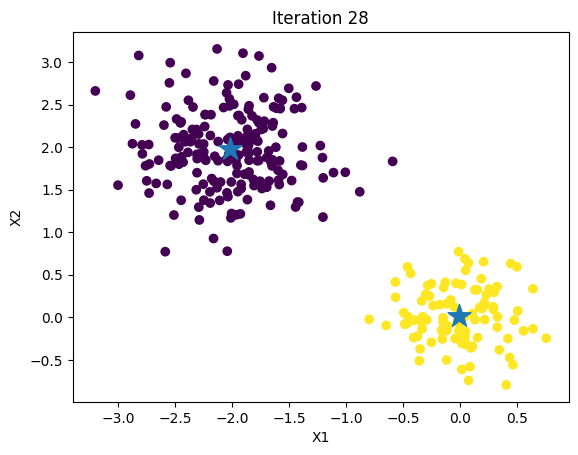

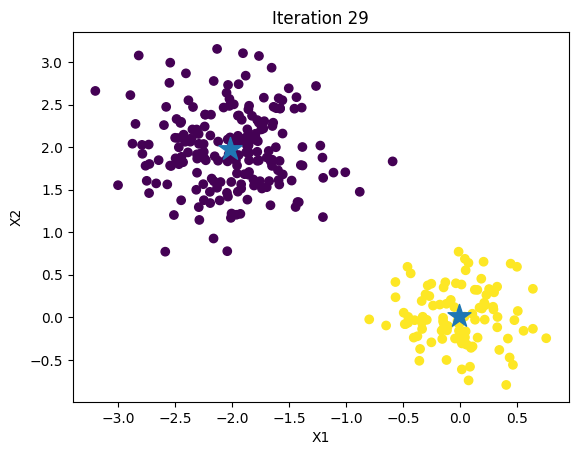

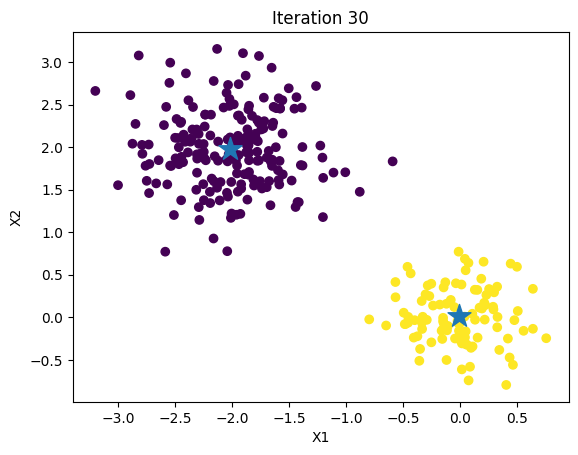

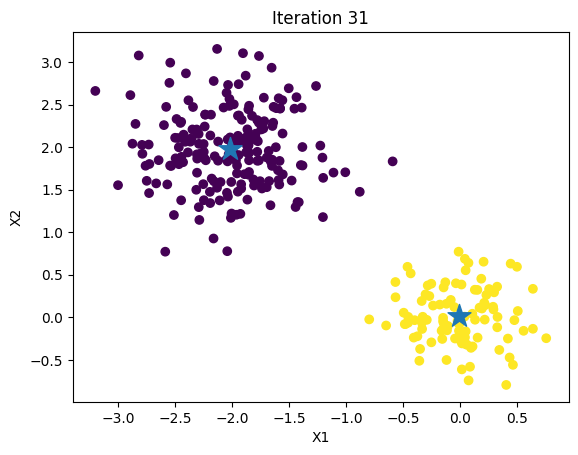

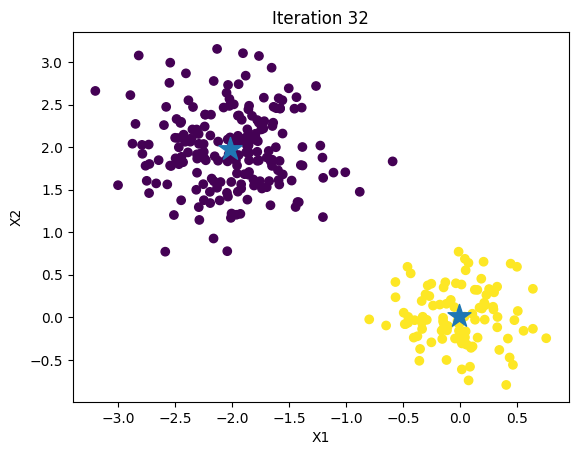

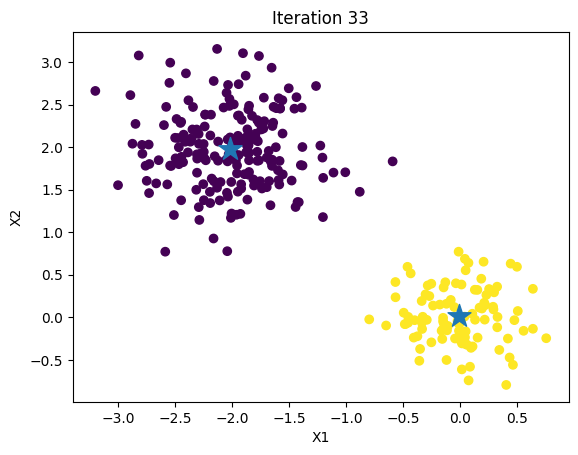

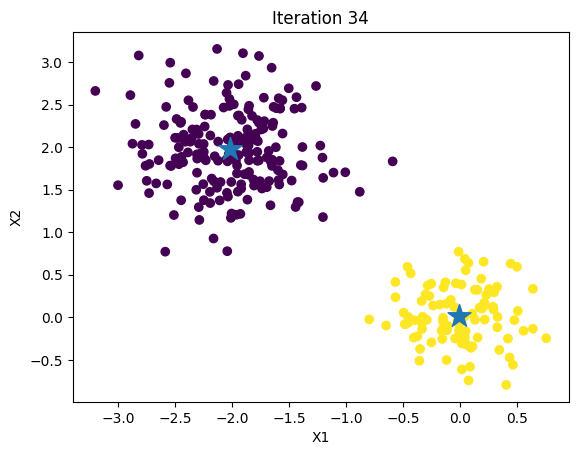

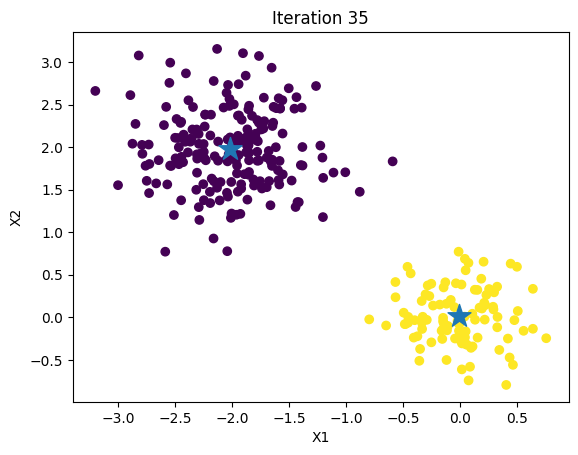

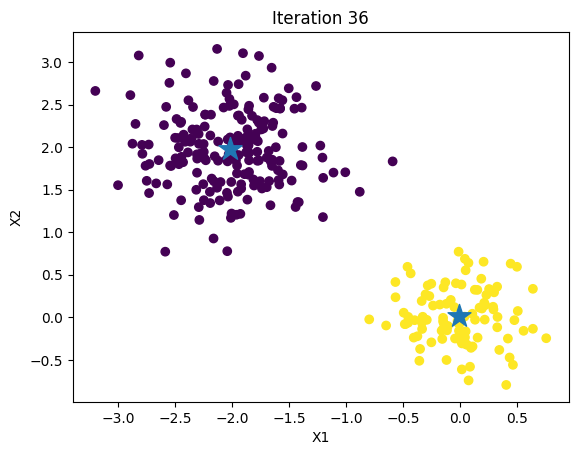

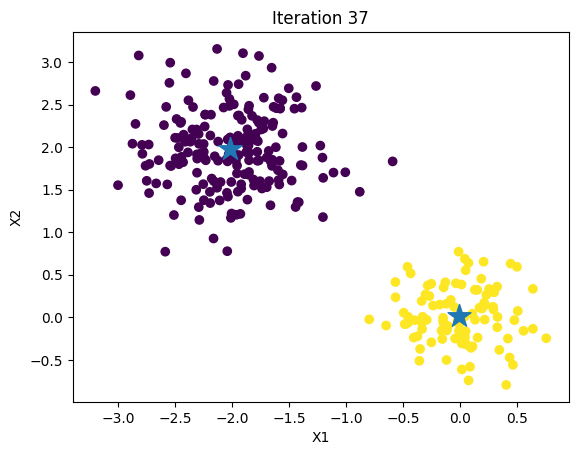

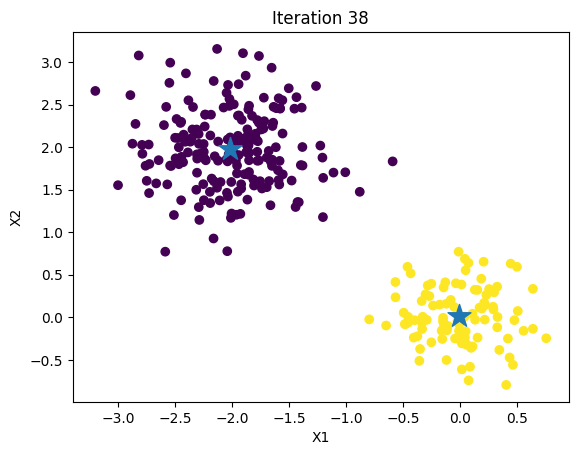

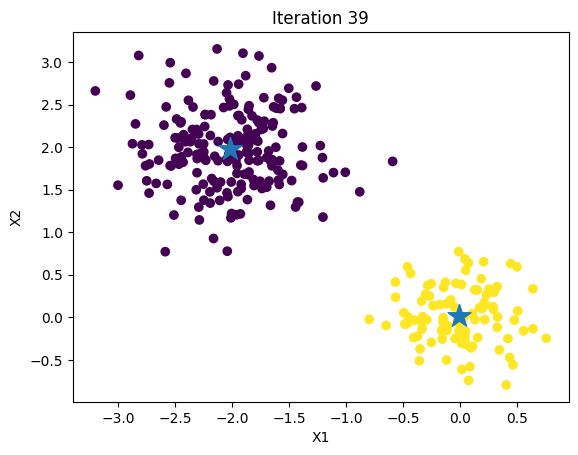

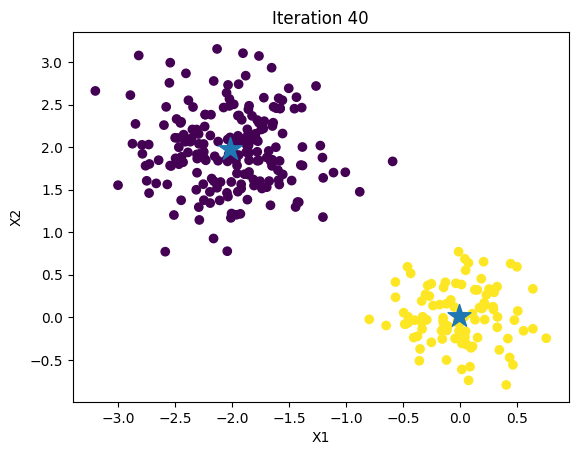

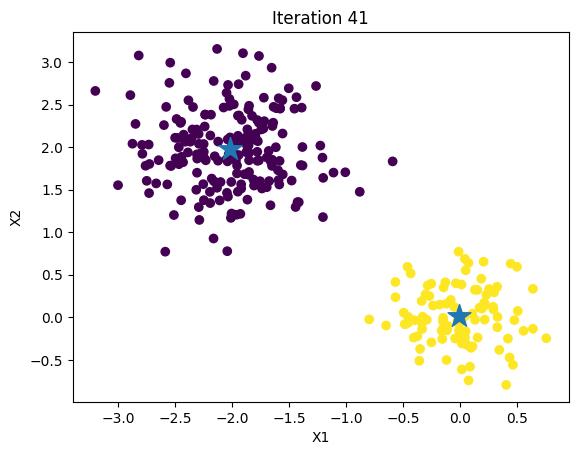

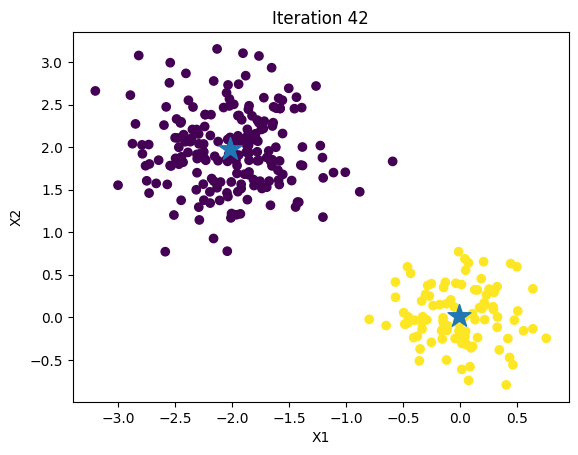

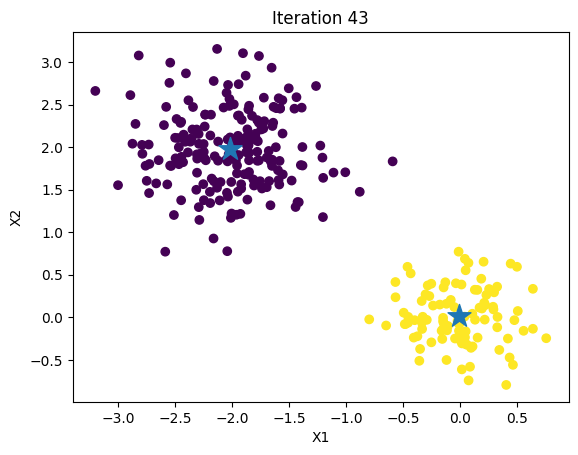

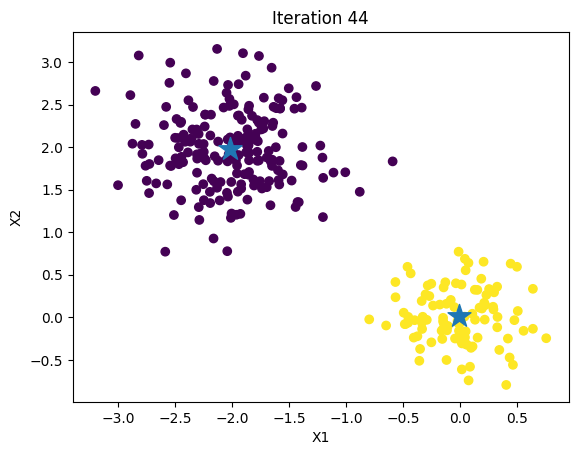

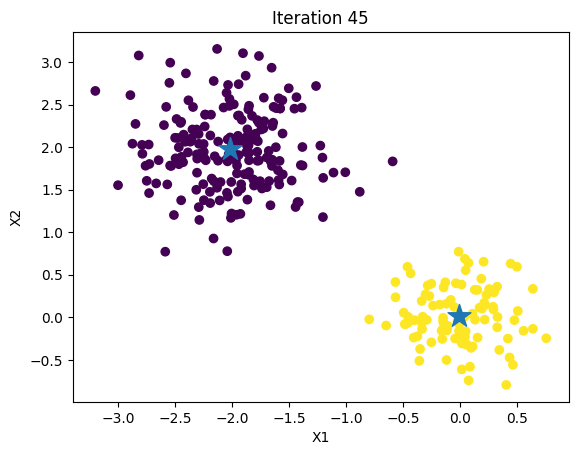

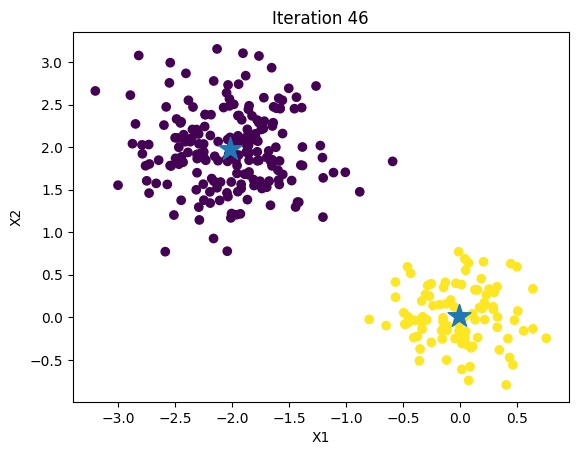

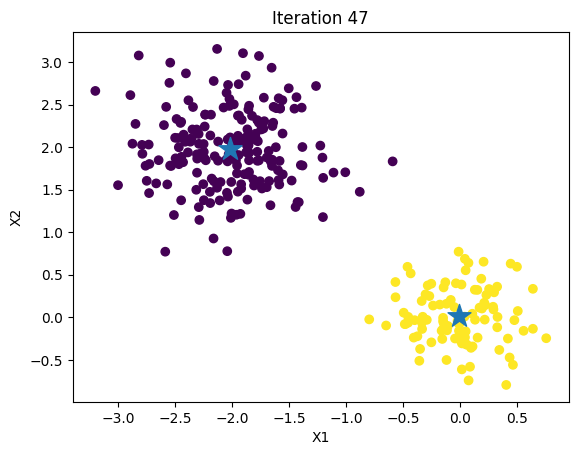

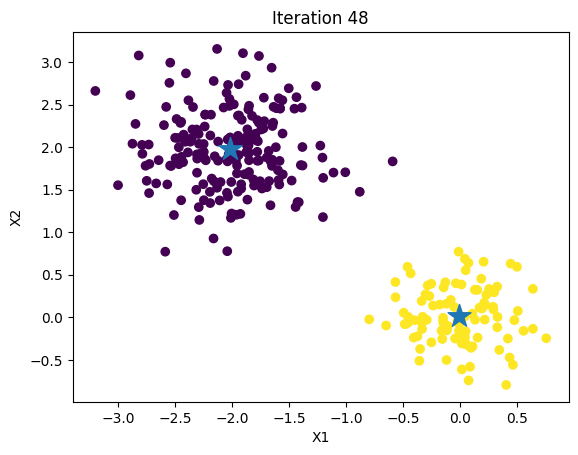

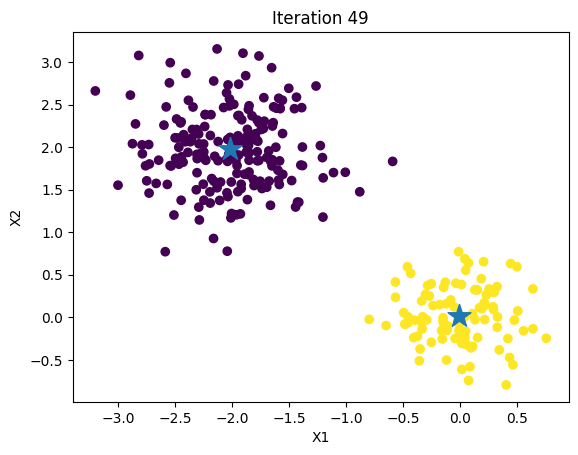

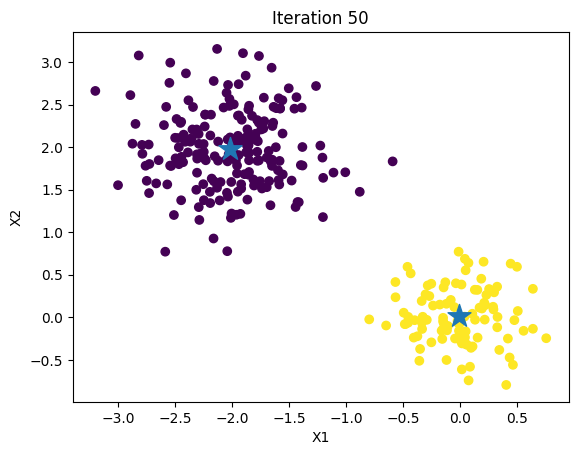

{'P': array([[4.05135513e-11, 1.00000000e+00],
        [2.82202333e-08, 9.99999972e-01],
        [6.92574692e-08, 9.99999931e-01],
        [1.41469940e-09, 9.99999999e-01],
        [4.07160874e-07, 9.99999593e-01],
        [4.43467573e-07, 9.99999557e-01],
        [1.05259355e-08, 9.99999989e-01],
        [1.75200922e-09, 9.99999998e-01],
        [5.90430332e-10, 9.99999999e-01],
        [9.46544003e-10, 9.99999999e-01],
        [1.90172728e-13, 1.00000000e+00],
        [3.83366385e-07, 9.99999617e-01],
        [1.78223628e-08, 9.99999982e-01],
        [5.75580205e-09, 9.99999994e-01],
        [1.19601430e-12, 1.00000000e+00],
        [8.17313322e-09, 9.99999992e-01],
        [8.21087655e-09, 9.99999992e-01],
        [2.44605325e-11, 1.00000000e+00],
        [1.31989985e-10, 1.00000000e+00],
        [2.09741254e-11, 1.00000000e+00],
        [1.53519506e-05, 9.99984648e-01],
        [1.89508255e-12, 1.00000000e+00],
        [1.90322663e-08, 9.99999981e-01],
        [1.24555901e-09, 9.99

<Figure size 640x480 with 0 Axes>

In [ ]:
EMalgo(X, K=2, n_iter=50, plot=True)

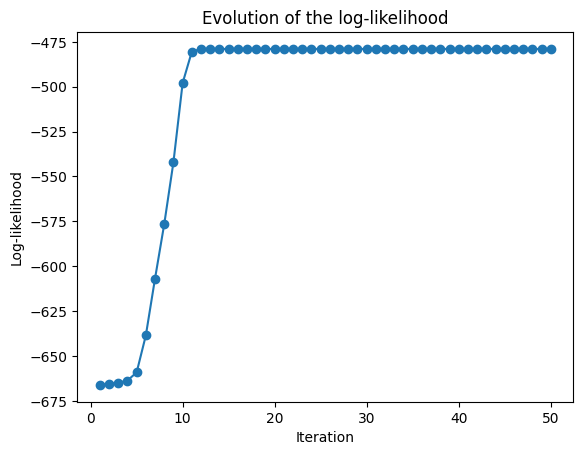

In [ ]:
plt.plot(
    range(1, len(res_EM['loglik']) + 1),
    res_EM['loglik'],
    marker="o"
)

plt.xlabel("Iteration")
plt.ylabel("Log-likelihood")
plt.title("Evolution of the log-likelihood")
plt.show()

In [ ]:
res_EM['loglik']

[np.float64(-666.0978440593868),
 np.float64(-665.5413699635831),
 np.float64(-664.9119758171694),
 np.float64(-663.6362000667991),
 np.float64(-659.1400469633998),
 np.float64(-638.5252659010762),
 np.float64(-606.823622794369),
 np.float64(-576.506643480043),
 np.float64(-542.0167872762519),
 np.float64(-497.91528579398044),
 np.float64(-480.44959262208954),
 np.float64(-478.94044760448776),
 np.float64(-478.93700533630073),
 np.float64(-478.9370044145745),
 np.float64(-478.93700441434993),
 np.float64(-478.9370044143498),
 np.float64(-478.93700441434993),
 np.float64(-478.93700441434993),
 np.float64(-478.93700441435),
 np.float64(-478.93700441435),
 np.float64(-478.9370044143499),
 np.float64(-478.9370044143499),
 np.float64(-478.9370044143499),
 np.float64(-478.9370044143499),
 np.float64(-478.9370044143499),
 np.float64(-478.9370044143499),
 np.float64(-478.9370044143499),
 np.float64(-478.9370044143499),
 np.float64(-478.9370044143499),
 np.float64(-478.9370044143499),
 np.float

## Question 1.5.

The correction for the following questions will be given next week !

How to select $K$, the number of groups, which is unknown in practice? Modify the function `EMalgo` to compute the BIC score. And select $K$.

The BIC score is defined as follows:
$$\textrm{BIC}=0.5 *b \log(n) - \hat{L}_c,$$
with
* $b$: the number of parameters estimated by the model
* $n$: the number of samples
* $\hat{L}_c$: the maximized value of the log-likelihood function

In practice, to compute $\hat{L}_c$ here, you can just take the last iteration of the EM algorithm.


## Question 1.6.

Use the function `GaussianMixture` of the scikit-learn module `sklearn.mixture` and compare the results. You can also compare the results with the k-mean algorithm using the function `KMeans` of the scikit-learn module `sklearn.cluster`.

## Question 1.7.

Apply the EM algorithm for the following data (more difficult). In particular, test whether BIC selects the correct value of $K$ in this case. Increase the parameter `cov_param` to make the data difficult to separate.

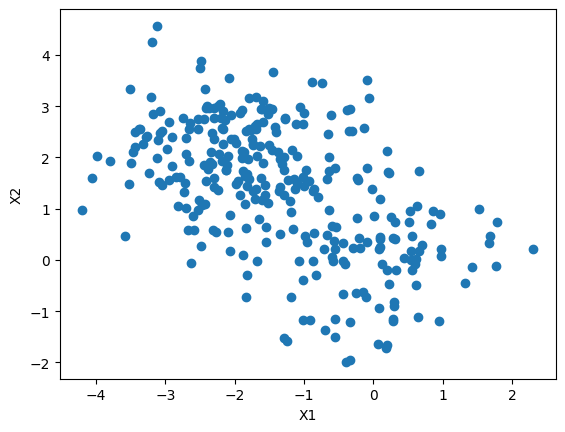

In [ ]:
cov_param = 0.8

X1 = np.random.multivariate_normal(
    mean=[0, 0],
    cov=cov_param * np.eye(2),
    size=100
)

X2 = np.random.multivariate_normal(
    mean=[-2, 2],
    cov=cov_param * np.eye(2),
    size=200
)

X = np.vstack((X1, X2))

plt.scatter(X[:, 0], X[:, 1])
plt.xlabel("X1")
plt.ylabel("X2")
plt.show()